<a href="https://colab.research.google.com/github/irfan060606/Scikit-Learn-Cookbook/blob/main/Chapter_4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 4 — Building Models with Distance Metrics and Nearest Neighbors

**Buku acuan:** *scikit-learn Cookbook*, Third Edition — John Sukup, Chapter 4.

Notebook ini mempelajari cara mengukur kedekatan antar-data, membangun model **K-Nearest Neighbors (KNN)**, membandingkan beberapa metrik jarak, memilih hyperparameter, dan mengevaluasi hasil klasifikasi maupun regresi.

Contoh di dalam notebook disusun sebagai latihan implementasi dengan dataset bawaan scikit-learn dan data sintetis, sehingga tidak memerlukan pengunduhan dataset eksternal.

## Tujuan pembelajaran

Setelah menyelesaikan notebook ini, kita diharapkan dapat:

1. Menjelaskan perbedaan jarak Euclidean, Manhattan, Minkowski, dan cosine.
2. Memahami cara kerja KNN untuk klasifikasi dan regresi.
3. Mengetahui mengapa scaling fitur sering diperlukan sebelum menghitung jarak.
4. Menguji pengaruh nilai `n_neighbors`, `weights`, dan `metric`.
5. Membaca metrik evaluasi seperti akurasi, precision, recall, F1-score, confusion matrix, MAE, dan RMSE.

## 1. Persiapan lingkungan

Library yang digunakan adalah NumPy untuk perhitungan numerik, pandas untuk menampilkan tabel, Matplotlib untuk visualisasi, dan scikit-learn untuk dataset serta algoritma machine learning.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris, make_circles
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
    learning_curve,
)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
    classification_report,
    mean_absolute_error,
    mean_squared_error,
)

SEED = 2026
np.random.seed(SEED)
pd.set_option("display.precision", 4)

print("NumPy version:", np.__version__)
print("Persiapan selesai.")

NumPy version: 2.1.3
Persiapan selesai.


## 2. Mengenal metrik jarak

KNN menentukan tetangga berdasarkan jarak antar titik. Pilihan metrik akan memengaruhi titik mana yang dianggap paling dekat.

Untuk dua vektor \(x\) dan \(y\):

- **Euclidean (L2):** \(d(x,y)=\sqrt{\sum_i (x_i-y_i)^2}\), yaitu jarak garis lurus.
- **Manhattan (L1):** \(d(x,y)=\sum_i |x_i-y_i|\), yaitu jumlah selisih absolut tiap koordinat.
- **Minkowski:** \(d(x,y)=\left(\sum_i |x_i-y_i|^p\right)^{1/p}\). Jika \(p=1\), hasilnya Manhattan; jika \(p=2\), hasilnya Euclidean.
- **Cosine distance:** mengukur perbedaan arah dua vektor, umumnya sebagai \(1-\text{cosine similarity}\). Ini sering berguna untuk representasi berdimensi tinggi, tetapi harus dipilih sesuai makna fitur.

Contoh berikut menghitung jarak secara langsung agar rumusnya lebih mudah dipahami.

In [2]:
point_a = np.array([2, 3])
point_b = np.array([5, 7])
difference = point_a - point_b

distance_examples = pd.DataFrame({
    "Metric": ["Euclidean", "Manhattan", "Minkowski (p=3)"],
    "Distance": [
        np.linalg.norm(difference, ord=2),
        np.linalg.norm(difference, ord=1),
        np.linalg.norm(difference, ord=3),
    ],
})
distance_examples

,Metric,Distance
0,Euclidean,5.0000
1,Manhattan,7.0000
2,Minkowski (p=3),4.4979


**Interpretasi:** jarak Manhattan biasanya lebih besar daripada atau sama dengan jarak Euclidean untuk dua titik yang sama. Nilai yang lebih kecil menunjukkan kedekatan yang lebih tinggi menurut metrik tersebut. Namun, jarak dari metrik yang berbeda tidak selalu bisa dibandingkan langsung untuk menentukan kualitas model.

### Mengapa skala fitur penting?

Misalnya, satu fitur diukur dalam sentimeter dengan nilai 1–10, sedangkan fitur lain berupa pendapatan dengan nilai ribuan. Tanpa scaling, fitur yang memiliki rentang besar dapat mendominasi perhitungan jarak. `StandardScaler` mengubah setiap fitur agar berpusat di sekitar rata-rata 0 dengan simpangan baku 1, berdasarkan data yang digunakan saat `fit`.

## 3. Memahami K-Nearest Neighbors (KNN)

KNN adalah algoritma *supervised learning* yang menggunakan contoh berlabel untuk membuat prediksi berdasarkan tetangga terdekat.

1. Hitung jarak data baru ke sampel pelatihan.
2. Pilih sebanyak \(k\) tetangga dengan jarak terkecil.
3. Pada **klasifikasi**, pilih kelas berdasarkan suara tetangga. Pada **regresi**, prediksi umumnya berupa rata-rata nilai target tetangga.

KNN sering disebut *lazy learner*: proses `fit` terutama menyimpan data pelatihan, sedangkan pencarian tetangga dilakukan saat prediksi. Dampaknya, model relatif sederhana tetapi prediksi bisa lebih lambat jika data pelatihan besar. Nilai `k` terlalu kecil dapat membuat model sensitif terhadap noise; nilai terlalu besar dapat membuat batas keputusan terlalu sederhana.

### 3.1 Menyiapkan data Iris

Dataset Iris berisi pengukuran bunga dari tiga spesies. Kita gunakan untuk contoh klasifikasi multi-kelas dan menjaga proporsi kelas pada pembagian data melalui `stratify=y`.

In [3]:
iris = load_iris()
X = iris.data
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    random_state=SEED,
    stratify=y,
)

print("Jumlah sampel:", X.shape[0])
print("Jumlah fitur:", X.shape[1])
print("Nama fitur:", iris.feature_names)
print("Kelas:", iris.target_names)
print("Sampel train:", len(X_train), "| sampel test:", len(X_test))
print("Distribusi kelas keseluruhan:", np.bincount(y))

Jumlah sampel: 150
Jumlah fitur: 4
Nama fitur: ['sepal length (cm)', 'sepal width (cm)', 'petal length (cm)', 'petal width (cm)']
Kelas: ['setosa' 'versicolor' 'virginica']
Sampel train: 112 | sampel test: 38
Distribusi kelas keseluruhan: [50 50 50]


### 3.2 Model KNN dasar dengan preprocessing

Di sini scaling dan klasifikasi dirangkai menggunakan `Pipeline`. Ketika model dipasangkan pada data pelatihan, scaler hanya mempelajari statistik dari data pelatihan. Saat memprediksi data uji, pipeline memakai parameter scaling yang sama sehingga mengurangi risiko *data leakage*.

In [4]:
baseline_knn = Pipeline([
    ("scaler", StandardScaler()),
    ("knn", KNeighborsClassifier(n_neighbors=5, metric="euclidean")),
])

baseline_knn.fit(X_train, y_train)
y_pred_baseline = baseline_knn.predict(X_test)
baseline_accuracy = accuracy_score(y_test, y_pred_baseline)

print(f"Akurasi KNN dasar: {baseline_accuracy:.3f}")
print("Contoh 5 label sebenarnya:", y_test[:5])
print("Contoh 5 hasil prediksi :", y_pred_baseline[:5])

Akurasi KNN dasar: 0.921
Contoh 5 label sebenarnya: [2 0 1 1 0]
Contoh 5 hasil prediksi : [2 0 1 1 0]


### 3.3 Melihat pola fitur

Kita gambar dua fitur petal (panjang dan lebar petal). Visualisasi dua fitur tidak menggambarkan keseluruhan empat fitur Iris, tetapi membantu melihat pola kelas yang mudah dipisahkan.

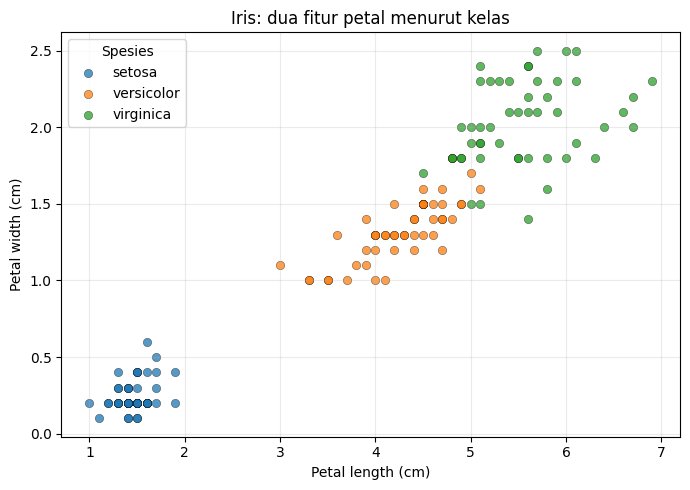

In [5]:
fig, ax = plt.subplots(figsize=(7, 5))
for class_id, class_name in enumerate(iris.target_names):
    mask = y == class_id
    ax.scatter(
        X[mask, 2], X[mask, 3],
        label=class_name, alpha=0.75, edgecolor="black", linewidth=0.3
    )
ax.set_xlabel("Petal length (cm)")
ax.set_ylabel("Petal width (cm)")
ax.set_title("Iris: dua fitur petal menurut kelas")
ax.legend(title="Spesies")
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

### 3.4 Pengaruh jumlah tetangga terhadap batas keputusan

Eksperimen ini menggunakan dua fitur petal agar bidang keputusan bisa digambar dalam dua dimensi. Model dengan nilai `k` kecil cenderung membentuk batas yang lebih rumit; nilai yang lebih besar menghasilkan batas yang lebih halus.

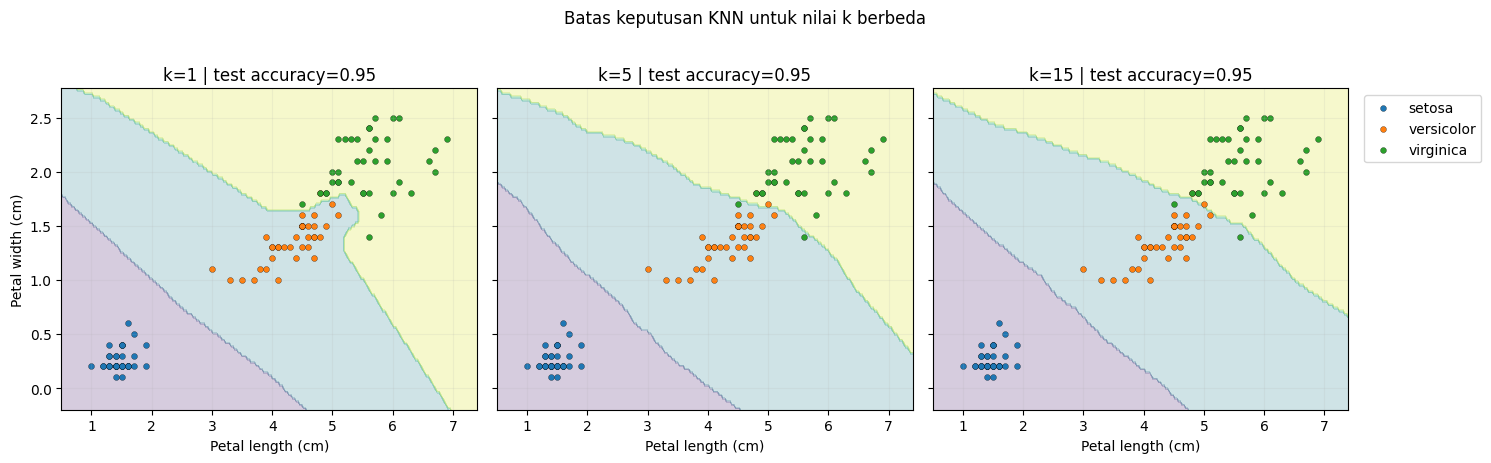

In [6]:
X_petals = iris.data[:, [2, 3]]
y_petals = iris.target
Xtr_p, Xte_p, ytr_p, yte_p = train_test_split(
    X_petals, y_petals,
    test_size=0.25,
    random_state=SEED,
    stratify=y_petals,
)

x_min, x_max = X_petals[:, 0].min() - 0.5, X_petals[:, 0].max() + 0.5
y_min, y_max = X_petals[:, 1].min() - 0.3, X_petals[:, 1].max() + 0.3
xx, yy = np.meshgrid(
    np.arange(x_min, x_max, 0.03),
    np.arange(y_min, y_max, 0.03),
)
grid = np.c_[xx.ravel(), yy.ravel()]

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
for ax, k in zip(axes, [1, 5, 15]):
    model = Pipeline([
        ("scale", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])
    model.fit(Xtr_p, ytr_p)
    region = model.predict(grid).reshape(xx.shape)
    score = accuracy_score(yte_p, model.predict(Xte_p))
    ax.contourf(xx, yy, region, alpha=0.22, cmap="viridis")
    for class_id, class_name in enumerate(iris.target_names):
        mask = ytr_p == class_id
        ax.scatter(Xtr_p[mask, 0], Xtr_p[mask, 1], s=18, label=class_name, edgecolor="black", linewidth=0.2)
    ax.set_title(f"k={k} | test accuracy={score:.2f}")
    ax.set_xlabel("Petal length (cm)")
    ax.grid(alpha=0.15)
axes[0].set_ylabel("Petal width (cm)")
axes[-1].legend(loc="upper left", bbox_to_anchor=(1.02, 1))
fig.suptitle("Batas keputusan KNN untuk nilai k berbeda", y=1.02)
plt.tight_layout()
plt.show()

**Hal yang perlu diamati:** jangan memilih `k` hanya karena batas keputusan terlihat bagus pada data latihan. Nilai `k` perlu diuji pada data yang tidak digunakan untuk melatih model atau melalui cross-validation.

## 4. Membandingkan metrik jarak

Buku membahas penggunaan lebih dari satu metrik, sebab bentuk distribusi data dapat memengaruhi hasil KNN. Berikut eksperimen dengan dua bentuk data sintetis: lingkaran yang saling bersarang dan pola papan catur. Kita membandingkan metrik Euclidean, Manhattan, Minkowski, dan cosine pada pembagian data yang sama.

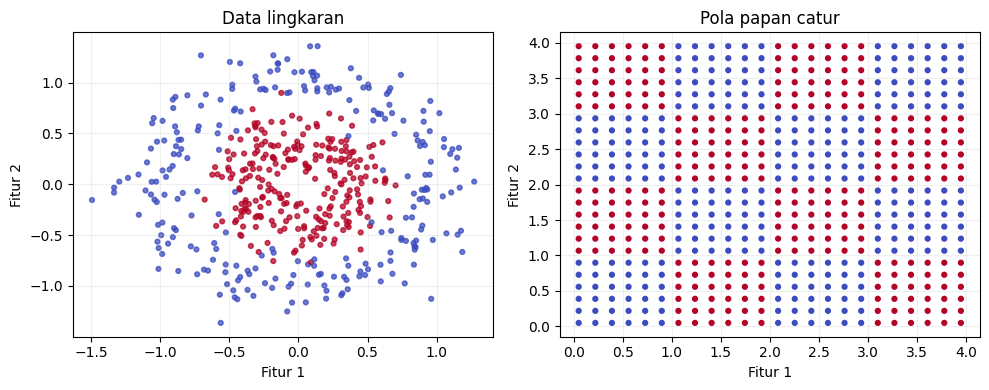

In [7]:
# Dataset A: dua lingkaran dengan sedikit noise
X_circle, y_circle = make_circles(
    n_samples=500,
    factor=0.42,
    noise=0.16,
    random_state=SEED,
)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(
    X_circle, y_circle, test_size=0.25, random_state=SEED, stratify=y_circle
)

# Dataset B: titik teratur dengan pola papan catur
n_side = 24
axis = np.linspace(0.05, 3.95, n_side)
xx_board, yy_board = np.meshgrid(axis, axis)
X_board = np.column_stack([xx_board.ravel(), yy_board.ravel()])
y_board = (
    np.floor(X_board[:, 0]).astype(int) + np.floor(X_board[:, 1]).astype(int)
) % 2
Xb_train, Xb_test, yb_train, yb_test = train_test_split(
    X_board, y_board, test_size=0.25, random_state=SEED, stratify=y_board
)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
axes[0].scatter(X_circle[:, 0], X_circle[:, 1], c=y_circle, cmap="coolwarm", s=12, alpha=0.75)
axes[0].set_title("Data lingkaran")
axes[1].scatter(X_board[:, 0], X_board[:, 1], c=y_board, cmap="coolwarm", s=12)
axes[1].set_title("Pola papan catur")
for ax in axes:
    ax.set_xlabel("Fitur 1")
    ax.set_ylabel("Fitur 2")
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

### 4.1 Menguji metrik pada dua dataset

Agar perbandingan adil, tiap metrik memakai data latih dan uji yang sama, nilai `k=7`, dan scaling melalui pipeline. Angka akurasi ini adalah hasil eksperimen pada dataset sintetis yang ditetapkan di atas, bukan jaminan untuk dataset lain.

In [8]:
metric_names = ["euclidean", "manhattan", "minkowski", "cosine"]
datasets = {
    "Lingkaran": (Xc_train, Xc_test, yc_train, yc_test),
    "Papan catur": (Xb_train, Xb_test, yb_train, yb_test),
}
metric_rows = []

for dataset_name, (Xtr, Xte, ytr, yte) in datasets.items():
    for metric_name in metric_names:
        model = Pipeline([
            ("scale", StandardScaler()),
            ("knn", KNeighborsClassifier(n_neighbors=7, metric=metric_name)),
        ])
        model.fit(Xtr, ytr)
        metric_rows.append({
            "Dataset": dataset_name,
            "Metrik": metric_name,
            "Akurasi uji": accuracy_score(yte, model.predict(Xte)),
        })

metric_results = pd.DataFrame(metric_rows)
display(metric_results.pivot(index="Metrik", columns="Dataset", values="Akurasi uji").round(3))

Dataset,Lingkaran,Papan catur
Metrik,,
cosine,0.464,0.785
euclidean,0.968,0.924
manhattan,0.960,0.924
minkowski,0.968,0.924


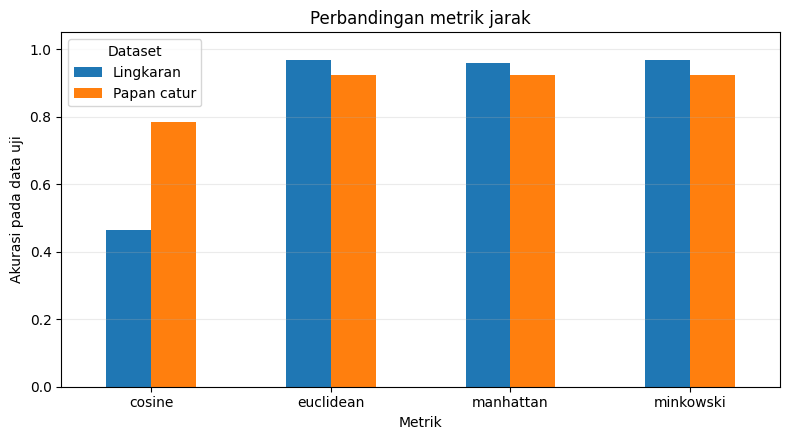

In [9]:
fig, ax = plt.subplots(figsize=(8, 4.5))
metric_results.pivot(index="Metrik", columns="Dataset", values="Akurasi uji").plot(
    kind="bar", ax=ax
)
ax.set_ylabel("Akurasi pada data uji")
ax.set_ylim(0, 1.05)
ax.set_title("Perbandingan metrik jarak")
ax.tick_params(axis="x", rotation=0)
ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

**Interpretasi:** hasil dapat berbeda di antara dataset karena setiap metrik mendefinisikan kedekatan dengan cara berbeda. Euclidean menggunakan selisih kuadrat, Manhattan menjumlahkan selisih absolut, Minkowski memungkinkan pemilihan parameter \(p\), sedangkan cosine berfokus pada arah vektor. Karena itu, metrik terbaik sebaiknya dipilih melalui validasi, bukan berdasarkan aturan universal.

## 5. Tuning hyperparameter KNN

Hyperparameter adalah pengaturan yang ditentukan sebelum proses pelatihan. Untuk KNN, beberapa pengaturan penting adalah:

- `n_neighbors`: jumlah tetangga yang digunakan.
- `weights`: `uniform` memberi bobot sama kepada semua tetangga, sedangkan `distance` memberi pengaruh lebih besar kepada tetangga yang lebih dekat.
- `metric`: cara menghitung jarak.

`GridSearchCV` mencoba kombinasi kandidat dan membandingkan skor cross-validation. Pencarian di bawah dilakukan hanya pada training set; test set tetap disimpan untuk evaluasi akhir.

In [10]:
cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
knn_pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("knn", KNeighborsClassifier()),
])
parameter_grid = {
    "knn__n_neighbors": [3, 5, 7, 9, 11, 13],
    "knn__weights": ["uniform", "distance"],
    "knn__metric": ["euclidean", "manhattan", "minkowski", "cosine"],
}

search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=parameter_grid,
    scoring="accuracy",
    cv=cv_strategy,
    n_jobs=-1,
    refit=True,
)
search.fit(X_train, y_train)

print("Kombinasi yang diuji:", len(search.cv_results_["params"]))
print("Parameter terbaik:", search.best_params_)
print(f"Rata-rata akurasi CV terbaik: {search.best_score_:.3f}")

Kombinasi yang diuji: 48
Parameter terbaik: {'knn__metric': 'manhattan', 'knn__n_neighbors': 9, 'knn__weights': 'uniform'}
Rata-rata akurasi CV terbaik: 0.973


### 5.1 Melihat beberapa konfigurasi terbaik

In [11]:
search_results = pd.DataFrame(search.cv_results_)
columns_to_show = [
    "param_knn__n_neighbors",
    "param_knn__weights",
    "param_knn__metric",
    "mean_test_score",
    "std_test_score",
]
best_configurations = search_results[columns_to_show].sort_values(
    "mean_test_score", ascending=False
).head(10).rename(columns={
    "param_knn__n_neighbors": "k",
    "param_knn__weights": "weights",
    "param_knn__metric": "metric",
    "mean_test_score": "mean CV accuracy",
    "std_test_score": "std CV accuracy",
})
display(best_configurations.reset_index(drop=True).round(4))

,k,weights,metric,mean CV accuracy,std CV accuracy
0,9,uniform,manhattan,0.9731,0.0220
1,9,distance,manhattan,0.9731,0.0220
2,9,uniform,euclidean,0.9727,0.0364
3,9,distance,euclidean,0.9727,0.0364
4,9,uniform,minkowski,0.9727,0.0364
5,9,distance,minkowski,0.9727,0.0364
6,3,uniform,euclidean,0.9644,0.0328
7,3,distance,euclidean,0.9644,0.0328
8,3,uniform,minkowski,0.9644,0.0328
9,3,distance,minkowski,0.9644,0.0328


### 5.2 Kurva pemilihan nilai k

Grid search menguji banyak parameter sekaligus. Sebagai pemeriksaan yang lebih sederhana, bagian ini mengukur rata-rata akurasi validasi untuk beberapa nilai `k` dengan metrik Euclidean. Kurva ini membantu menunjukkan kecenderungan, bukan selalu menghasilkan pilihan terbaik untuk seluruh kombinasi parameter.

,k,mean_cv_accuracy,std_cv_accuracy
0,1,0.9640,0.0339
1,3,0.9644,0.0328
2,5,0.9466,0.0512
3,7,0.9640,0.0339
4,9,0.9727,0.0364
5,11,0.9549,0.0288
6,13,0.9549,0.0407
7,15,0.9549,0.0407
8,17,0.9368,0.0618
9,19,0.9103,0.0646


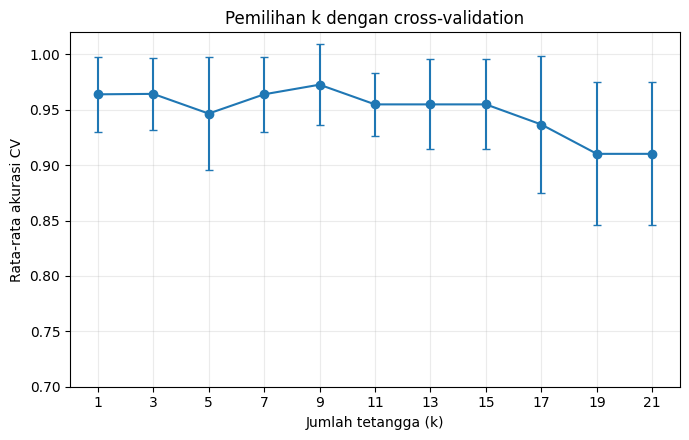

In [12]:
k_candidates = list(range(1, 22, 2))
k_means = []
k_stds = []
for k in k_candidates:
    candidate = Pipeline([
        ("scale", StandardScaler()),
        ("knn", KNeighborsClassifier(n_neighbors=k, metric="euclidean")),
    ])
    scores = cross_val_score(
        candidate, X_train, y_train,
        cv=cv_strategy, scoring="accuracy", n_jobs=-1
    )
    k_means.append(scores.mean())
    k_stds.append(scores.std())

k_curve = pd.DataFrame({"k": k_candidates, "mean_cv_accuracy": k_means, "std_cv_accuracy": k_stds})
display(k_curve.round(4))

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.errorbar(k_candidates, k_means, yerr=k_stds, marker="o", capsize=3)
ax.set_xlabel("Jumlah tetangga (k)")
ax.set_ylabel("Rata-rata akurasi CV")
ax.set_title("Pemilihan k dengan cross-validation")
ax.set_xticks(k_candidates)
ax.set_ylim(0.7, 1.02)
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 6. Evaluasi model

Skor yang baik pada training set saja belum membuktikan model mampu melakukan generalisasi. Kita mengevaluasi estimator terbaik di data uji yang belum dilihat selama tuning.

- **Accuracy:** proporsi prediksi yang benar.
- **Precision:** dari prediksi suatu kelas, proporsi yang benar.
- **Recall:** dari seluruh data yang benar-benar termasuk kelas itu, proporsi yang terdeteksi.
- **F1-score:** rata-rata harmonik precision dan recall.
- **Confusion matrix:** memperlihatkan pasangan label aktual dan prediksi.

Akurasi test set: 0.921

Classification report:
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        13
  versicolor       0.86      0.92      0.89        13
   virginica       0.91      0.83      0.87        12

    accuracy                           0.92        38
   macro avg       0.92      0.92      0.92        38
weighted avg       0.92      0.92      0.92        38



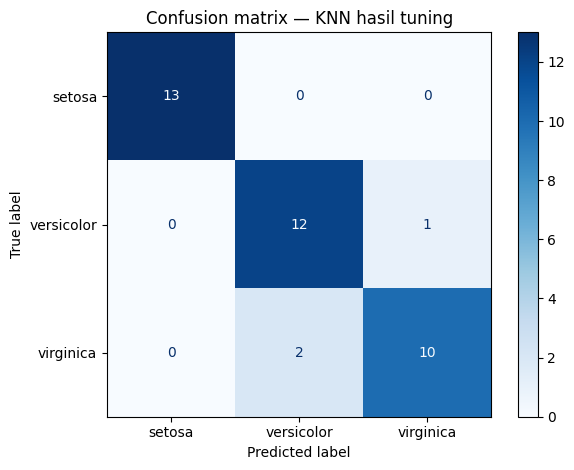

In [13]:
best_knn = search.best_estimator_
y_pred = best_knn.predict(X_test)
final_accuracy = accuracy_score(y_test, y_pred)

print(f"Akurasi test set: {final_accuracy:.3f}")
print("\nClassification report:")
print(classification_report(y_test, y_pred, target_names=iris.target_names, zero_division=0))

cm = confusion_matrix(y_test, y_pred)
display_matrix = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=iris.target_names)
display_matrix.plot(cmap="Blues", values_format="d")
plt.title("Confusion matrix — KNN hasil tuning")
plt.tight_layout()
plt.show()

### 6.1 Stabilitas skor dengan cross-validation

Cross-validation membagi data pelatihan ke beberapa fold. Setiap fold bergantian menjadi validasi sementara; skor rata-rata menunjukkan performa secara lebih stabil dibanding hanya mengandalkan satu pembagian data.

In [14]:
cv_scores = cross_val_score(
    best_knn, X_train, y_train,
    cv=cv_strategy, scoring="accuracy", n_jobs=-1
)
print("Skor tiap fold:", np.round(cv_scores, 3))
print(f"Rata-rata: {cv_scores.mean():.3f}")
print(f"Simpangan baku: {cv_scores.std():.3f}")

Skor tiap fold: [1.    0.957 0.955 0.955 1.   ]
Rata-rata: 0.973
Simpangan baku: 0.022


### 6.2 Learning curve

Learning curve membandingkan skor training dan validasi ketika jumlah data pelatihan ditingkatkan. Kurva ini dapat membantu mendeteksi apakah penambahan data berpotensi memperbaiki hasil, tetapi interpretasinya perlu mempertimbangkan ukuran dataset dan variasi pada setiap fold.

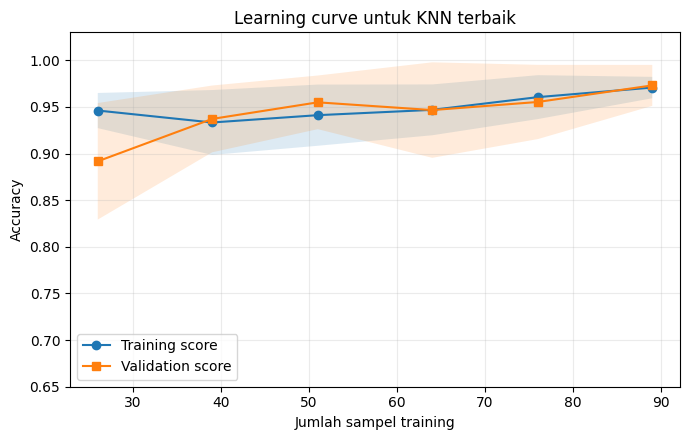

In [15]:
train_sizes, train_scores, validation_scores = learning_curve(
    best_knn,
    X_train,
    y_train,
    train_sizes=np.linspace(0.3, 1.0, 6),
    cv=cv_strategy,
    scoring="accuracy",
    n_jobs=-1,
)

train_mean = train_scores.mean(axis=1)
validation_mean = validation_scores.mean(axis=1)
train_std = train_scores.std(axis=1)
validation_std = validation_scores.std(axis=1)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(train_sizes, train_mean, marker="o", label="Training score")
ax.plot(train_sizes, validation_mean, marker="s", label="Validation score")
ax.fill_between(train_sizes, train_mean-train_std, train_mean+train_std, alpha=0.15)
ax.fill_between(train_sizes, validation_mean-validation_std, validation_mean+validation_std, alpha=0.15)
ax.set_xlabel("Jumlah sampel training")
ax.set_ylabel("Accuracy")
ax.set_title("Learning curve untuk KNN terbaik")
ax.set_ylim(0.65, 1.03)
ax.legend()
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 7. KNN untuk regresi

KNN bukan hanya untuk klasifikasi. Pada regresi, nilai target untuk data baru diperkirakan dari nilai target tetangga terdekat, biasanya melalui rata-rata; dengan `weights="distance"`, tetangga yang lebih dekat memiliki bobot lebih besar.

Contoh berikut menggunakan data sintetis satu dimensi dengan pola sinus dan noise. Ini bertujuan menunjukkan penggunaan `KNeighborsRegressor`, bukan untuk membuat model prediksi dunia nyata.

In [16]:
reg_rng = np.random.default_rng(SEED)
X_reg = reg_rng.uniform(0, 10, size=(180, 1))
y_reg = np.sin(X_reg[:, 0]) + reg_rng.normal(0, 0.15, size=180)

Xr_train, Xr_test, yr_train, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.25, random_state=SEED
)
regressor = KNeighborsRegressor(n_neighbors=7, weights="distance")
regressor.fit(Xr_train, yr_train)
yr_pred = regressor.predict(Xr_test)

mae = mean_absolute_error(yr_test, yr_pred)
rmse = np.sqrt(mean_squared_error(yr_test, yr_pred))
print(f"MAE  : {mae:.3f}")
print(f"RMSE : {rmse:.3f}")

MAE  : 0.138
RMSE : 0.185


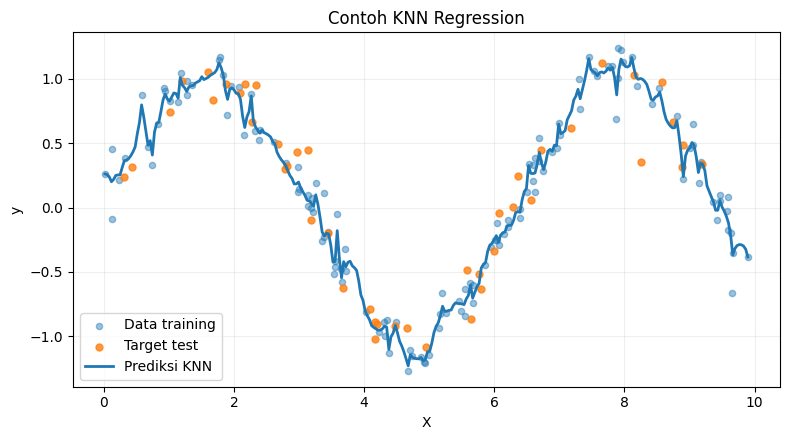

In [17]:
x_line = np.linspace(X_reg.min(), X_reg.max(), 300).reshape(-1, 1)
y_line = regressor.predict(x_line)
order = np.argsort(Xr_test[:, 0])

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(Xr_train[:, 0], yr_train, alpha=0.45, s=20, label="Data training")
ax.scatter(Xr_test[:, 0], yr_test, alpha=0.8, s=25, label="Target test")
ax.plot(x_line[:, 0], y_line, linewidth=2, label="Prediksi KNN")
ax.set_xlabel("X")
ax.set_ylabel("y")
ax.set_title("Contoh KNN Regression")
ax.legend()
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 8. Ringkasan Chapter 4

- **Metrik jarak** menentukan seberapa dekat dua sampel. Euclidean menghitung jarak lurus, Manhattan menjumlahkan selisih absolut, Minkowski menggeneralisasi keduanya, dan cosine membandingkan arah vektor.
- **KNN** membuat prediksi berdasarkan tetangga terdekat. `k` kecil lebih sensitif terhadap contoh individual; `k` besar cenderung menghaluskan keputusan.
- **Scaling** penting saat fitur memakai skala berbeda. Melakukan preprocessing di dalam `Pipeline` membantu menjaga prosedur konsisten antara data training dan data uji.
- **Pemilihan parameter** sebaiknya memakai cross-validation. `GridSearchCV` mengevaluasi kombinasi parameter, bukan hanya satu nilai `k`.
- **Evaluasi** perlu lebih dari satu sudut pandang: accuracy, confusion matrix, precision, recall, F1-score, dan cross-validation untuk klasifikasi; MAE dan RMSE dapat dipakai pada contoh regresi.
- **Tidak ada metrik atau nilai k yang selalu terbaik.** Pilihan harus mengikuti karakteristik data dan tujuan masalah.

### Referensi

Sukup, John. *scikit-learn Cookbook*, Third Edition. Packt Publishing, 2025. Chapter 4: **Building Models with Distance Metrics and Nearest Neighbors**.

Buku ini digunakan sebagai rujukan struktur dan konsep. Notebook ini merupakan implementasi pembelajaran dengan eksperimen dan penjelasan yang ditulis untuk latihan ini.